In [ ]:
import pandas as pd
import numpy as np
import tensorflow as tf

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from pathlib import Path


tf.keras.utils.set_random_seed(42)

PROJECT_DIR = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "data" / "processed").is_dir()),
    None
)

if PROJECT_DIR is None:
    raise FileNotFoundError(
        "No se encontró data/processed del proyecto."
    )

DATA_DIR = PROJECT_DIR / "data" / "processed"

train = pd.read_csv(DATA_DIR / "ghi_multisitio_entrenamiento.csv")
validacion = pd.read_csv(DATA_DIR / "ghi_multisitio_validacion.csv")
test = pd.read_csv(DATA_DIR / "ghi_multisitio_prueba.csv")

print("Train:", train.shape)
print("Validación:", validacion.shape)
print("Test:", test.shape)


Train: (262944, 16)
Validación: (52560, 16)
Test: (25992, 16)


In [ ]:
#definir variables
features = [
    "ghi",
    "ghi_lag_1",
    "ghi_lag_24",
    "temp",
    "vel",
    "cloud",
    "hora_sin",
    "hora_cos",
    "dia_anio_sin",
    "dia_anio_cos",
    "colchane",
    "pica"
]

target = "ghi_t1"

columnas_necesarias = features + [target]

train = train.dropna(subset=columnas_necesarias).copy()
validacion = validacion.dropna(subset=columnas_necesarias).copy()
test = test.dropna(subset=columnas_necesarias).copy()

In [ ]:
#preparar entradas y objetivo
X_train = train[features]
y_train = train[[target]]

X_valid = validacion[features]
y_valid = validacion[[target]]

X_test = test[features]
y_test = test[[target]]

In [ ]:
#escalar datos
scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_train_scaled = scaler_X.fit_transform(X_train)
X_valid_scaled = scaler_X.transform(X_valid)
X_test_scaled = scaler_X.transform(X_test)

y_train_scaled = scaler_y.fit_transform(y_train).ravel()
y_valid_scaled = scaler_y.transform(y_valid).ravel()

In [ ]:
#definir configuraciones
configuraciones_mlp = {
    "MLP 1": [32],
    "MLP 2": [64, 32]
}

#MLP 1: una capa oculta de 32 neuronas.
#MLP 2: dos capas ocultas de 64 y 32 neuronas.

In [ ]:
#función para crear modelo
def crear_mlp(capas):
    modelo = tf.keras.Sequential()

    modelo.add(
        tf.keras.layers.Input(shape=(len(features),))
    )

    for neuronas in capas:
        modelo.add(
            tf.keras.layers.Dense(
                neuronas,
                activation="relu"
            )
        )

    modelo.add(
        tf.keras.layers.Dense(1)
    )

    modelo.compile(
        optimizer="adam",
        loss="mse"
    )

    return modelo

In [ ]:
#validar configuraciones
resultados_validacion_mlp = []
modelos_mlp = {}

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
)

for nombre, capas in configuraciones_mlp.items():

    print(f"\nEntrenando {nombre}")

    modelo = crear_mlp(capas)

    historia = modelo.fit(
        X_train_scaled,
        y_train_scaled,
        validation_data=(
            X_valid_scaled,
            y_valid_scaled
        ),
        epochs=100,
        batch_size=256,
        callbacks=[early_stopping],
        verbose=0
    )

    pred_scaled = modelo.predict(
        X_valid_scaled,
        verbose=0
    )

    pred_valid = scaler_y.inverse_transform(
        pred_scaled
    ).ravel()

    pred_valid = np.clip(pred_valid, 0, None)

    reales = y_valid[target].to_numpy()

    mae = mean_absolute_error(
        reales,
        pred_valid
    )

    rmse = np.sqrt(
        mean_squared_error(
            reales,
            pred_valid
        )
    )

    r2 = r2_score(
        reales,
        pred_valid
    )

    resultados_validacion_mlp.append({
        "Configuración": nombre,
        "Capas ocultas": str(capas),
        "Épocas ejecutadas": len(historia.history["loss"]),
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

    modelos_mlp[nombre] = modelo


Entrenando MLP 1

Entrenando MLP 2


In [ ]:
#mostrar resultados
tabla_validacion_mlp = pd.DataFrame(
    resultados_validacion_mlp
).sort_values("MAE")

display(tabla_validacion_mlp)

,Configuración,Capas ocultas,Épocas ejecutadas,MAE,RMSE,R2
0,MLP 1,[32],75,20.739161,66.318018,0.971026
1,MLP 2,"[64, 32]",8,24.299992,68.558885,0.969035


In [ ]:
#entrenamiento final de MLP (train+validacion)
train_final = pd.concat(
    [train, validacion],
    ignore_index=True
)

train_final = train_final.dropna(
    subset=columnas_necesarias
).copy()

test = test.dropna(
    subset=columnas_necesarias
).copy()

print("Entrenamiento final:", train_final.shape)
print("Test:", test.shape)

Entrenamiento final: (315504, 16)
Test: (25989, 16)


In [ ]:
#escalar nuevamente
scaler_X_final = StandardScaler()
scaler_y_final = StandardScaler()

X_train_final = scaler_X_final.fit_transform(
    train_final[features]
)

y_train_final = scaler_y_final.fit_transform(
    train_final[[target]]
).ravel()

X_test_final = scaler_X_final.transform(
    test[features]
)

y_test_final = test[target].to_numpy()

In [ ]:
#crear y entrenar modelo final
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

modelo_mlp_final = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(len(features),)),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(1)
])

modelo_mlp_final.compile(
    optimizer="adam",
    loss="mse"
)

historia_final = modelo_mlp_final.fit(
    X_train_final,
    y_train_final,
    epochs=75,
    batch_size=256,
    shuffle=True,
    verbose=0
)

print("Modelo MLP final entrenado.")

Modelo MLP final entrenado.


In [ ]:
#predecir y calcular métricas
pred_test_scaled = modelo_mlp_final.predict(
    X_test_final,
    verbose=0
)

pred_test_mlp_original = scaler_y_final.inverse_transform(
    pred_test_scaled
).ravel()

pred_test_mlp = np.clip(
    pred_test_mlp_original,
    0,
    None
)

mae_mlp = mean_absolute_error(
    y_test_final,
    pred_test_mlp
)

rmse_mlp = np.sqrt(
    mean_squared_error(
        y_test_final,
        pred_test_mlp
    )
)

r2_mlp = r2_score(
    y_test_final,
    pred_test_mlp
)

print("MLP FINAL")
print(f"MAE:  {mae_mlp:.4f} W/m²")
print(f"RMSE: {rmse_mlp:.4f} W/m²")
print(f"R²:   {r2_mlp:.4f}")

MLP FINAL
MAE:  17.7323 W/m²
RMSE: 55.0991 W/m²
R²:   0.9805


In [ ]:
#crear tablas de predicciones
resultados_test_mlp = test[
    ["fecha_hora", "comuna", target]
].copy()

# Convertir 'fecha_hora' a tipo datetime
resultados_test_mlp["fecha_hora"] = pd.to_datetime(
    resultados_test_mlp["fecha_hora"]
)

resultados_test_mlp["fecha_objetivo"] = (
    resultados_test_mlp["fecha_hora"]
    + pd.Timedelta(hours=1)
)

resultados_test_mlp["ghi_real"] = y_test_final
resultados_test_mlp["ghi_pronosticado"] = pred_test_mlp

resultados_test_mlp["residuo"] = (
    resultados_test_mlp["ghi_real"]
    - resultados_test_mlp["ghi_pronosticado"]
)

display(resultados_test_mlp.head())

,fecha_hora,comuna,ghi_t1,fecha_objetivo,ghi_real,ghi_pronosticado,residuo
0,2016-01-01 00:00:00,colchane,0.0,2016-01-01 01:00:00,0.0,8.467745,-8.467745
1,2016-01-01 01:00:00,colchane,0.0,2016-01-01 02:00:00,0.0,2.237643,-2.237643
2,2016-01-01 02:00:00,colchane,0.0,2016-01-01 03:00:00,0.0,2.260927,-2.260927
3,2016-01-01 03:00:00,colchane,0.0,2016-01-01 04:00:00,0.0,0.000000,0.000000
4,2016-01-01 04:00:00,colchane,0.0,2016-01-01 05:00:00,0.0,0.000000,0.000000


In [ ]:
#resultados por localidad
metricas_mlp_localidad = []

for comuna, grupo in resultados_test_mlp.groupby("comuna"):

    metricas_mlp_localidad.append({
        "Localidad": comuna,
        "MAE": mean_absolute_error(
            grupo["ghi_real"],
            grupo["ghi_pronosticado"]
        ),
        "RMSE": np.sqrt(
            mean_squared_error(
                grupo["ghi_real"],
                grupo["ghi_pronosticado"]
            )
        ),
        "R2": r2_score(
            grupo["ghi_real"],
            grupo["ghi_pronosticado"]
        )
    })

metricas_mlp_localidad = pd.DataFrame(
    metricas_mlp_localidad
)

display(metricas_mlp_localidad)

,Localidad,MAE,RMSE,R2
0,colchane,26.571121,73.003135,0.967727
1,pica,13.204895,42.476314,0.988150
2,pozo_almonte,13.420924,44.430273,0.986774


In [ ]:
#residuos
print(
    "Media de residuos:",
    resultados_test_mlp["residuo"].mean()
)

print(
    "Desviación estándar:",
    resultados_test_mlp["residuo"].std()
)

print(
    "Predicciones negativas originales:",
    np.sum(pred_test_mlp_original < 0)
)

Media de residuos: -0.7918622055266821
Desviación estándar: 55.094504683025505
Predicciones negativas originales: 6561


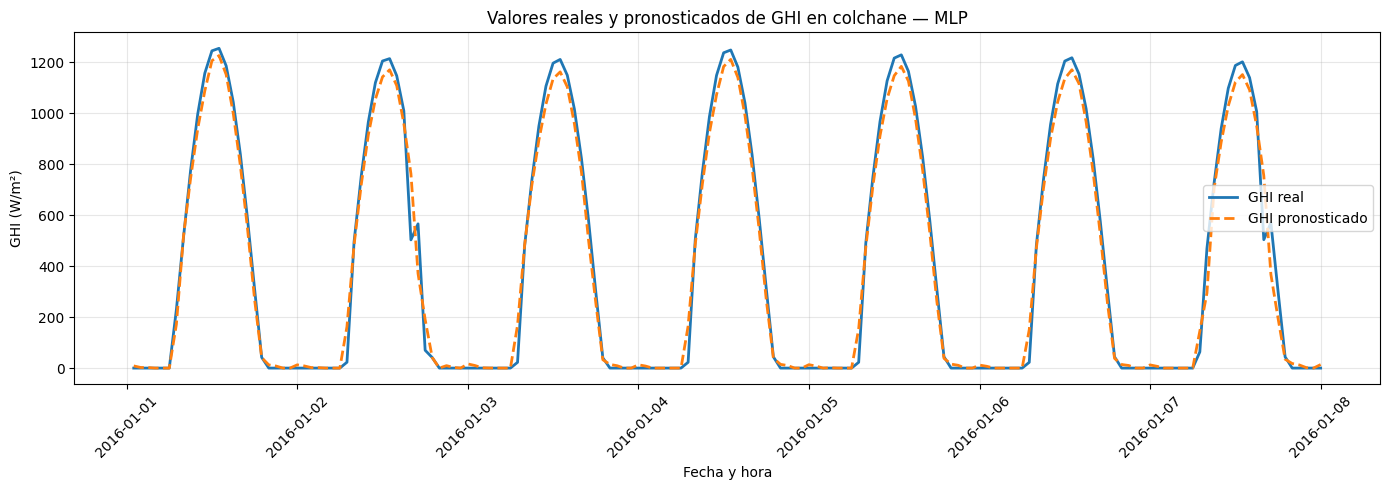

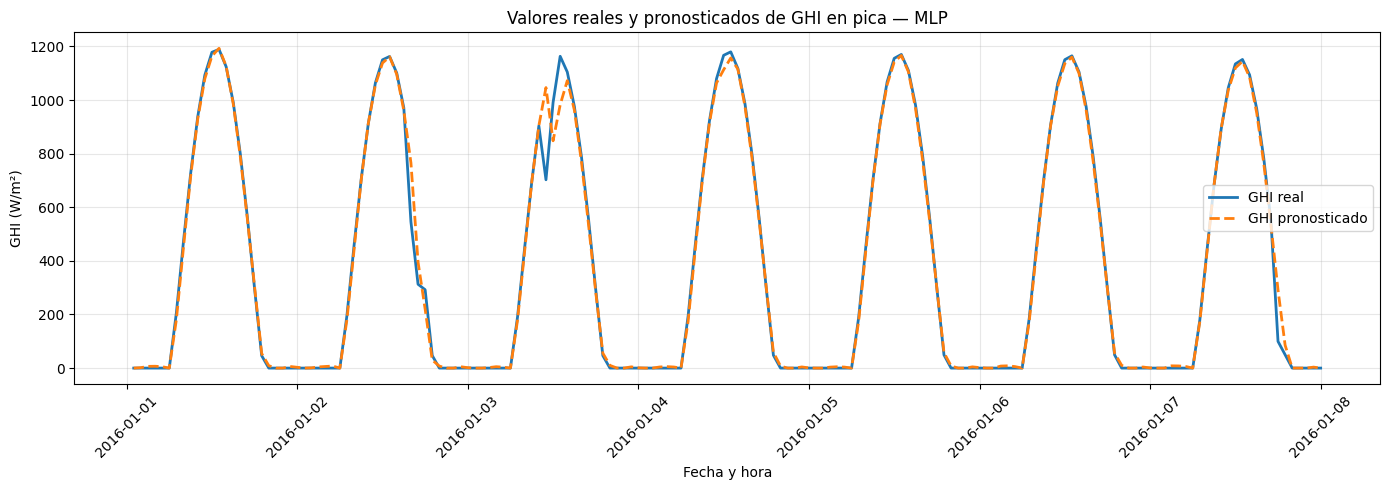

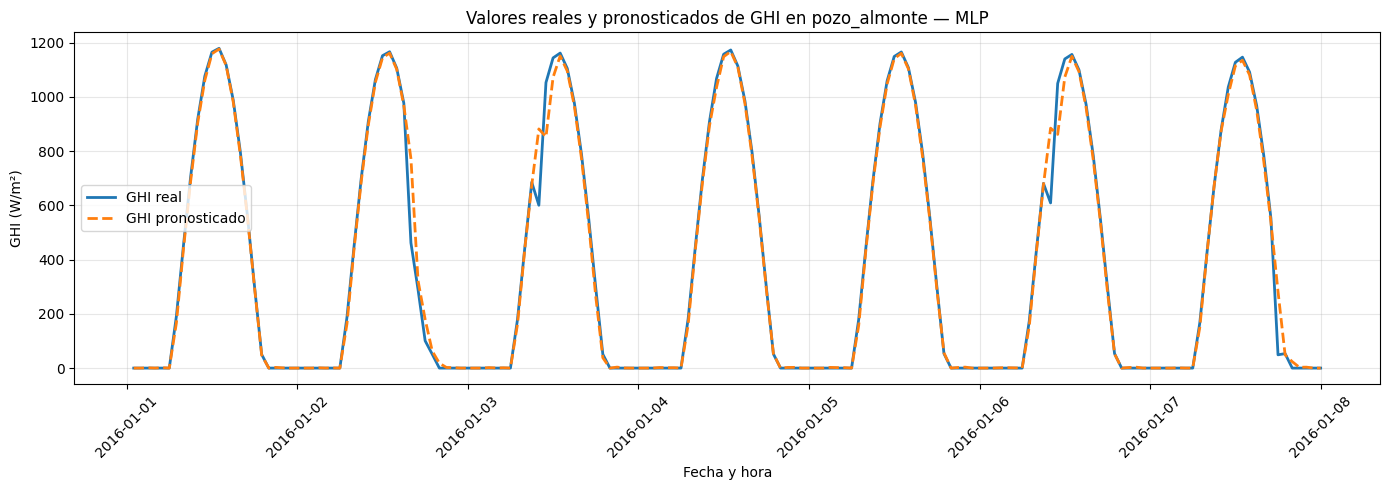

In [ ]:
#gráficos por localidad
import matplotlib.pyplot as plt


FIGURES_DIR = PROJECT_DIR / "results" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)


for comuna in resultados_test_mlp["comuna"].unique():

    muestra = (
        resultados_test_mlp[
            resultados_test_mlp["comuna"] == comuna
        ]
        .sort_values("fecha_objetivo")
        .head(24 * 7)
    )

    plt.figure(figsize=(14, 5))

    plt.plot(
        muestra["fecha_objetivo"],
        muestra["ghi_real"],
        label="GHI real",
        linewidth=2
    )

    plt.plot(
        muestra["fecha_objetivo"],
        muestra["ghi_pronosticado"],
        label="GHI pronosticado",
        linestyle="--",
        linewidth=2
    )

    plt.title(
        f"Valores reales y pronosticados de GHI en {comuna} — MLP"
    )

    plt.xlabel("Fecha y hora")
    plt.ylabel("GHI (W/m²)")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.xticks(rotation=45)
    plt.tight_layout()


    plt.savefig(
        FIGURES_DIR / f"mlp_real_vs_pronosticado_{comuna}.png",
        dpi=300,
        bbox_inches="tight"
    )



    plt.show()

In [ ]:
#Guardar modelo y escaladores
import joblib

# Carpeta para guardar el modelo y sus escaladores
ruta_modelos = PROJECT_DIR / "models" / "mlp"
ruta_modelos.mkdir(parents=True, exist_ok=True)


Mounted at /content/drive


In [ ]:

modelo_mlp_final.save(
    ruta_modelos / "modelo_mlp_final.keras"
)

joblib.dump(
    scaler_X_final,
    ruta_modelos / "scaler_X_mlp.joblib"
)

joblib.dump(
    scaler_y_final,
    ruta_modelos / "scaler_y_mlp.joblib"
)

print("Modelo MLP y escaladores guardados correctamente.")

['/content/drive/MyDrive/modelos_radiacion/scaler_y_mlp.joblib']